# Thu nhập 2010–2014 — bỏ top 0,1% mỗi năm

**Bản làm việc theo lựa chọn ngày 09/11/2026.** Loại 10 hộ có **thu nhập đầu người** cao nhất của từng năm; đây là quy tắc giới hạn đối tượng phân tích, không phải sửa lỗi dữ liệu.

Bốn câu hỏi áp dụng cho phần hộ **ngoài top 0,1%**:

1. Thu nhập bình quân đầu người có tăng không?
2. Thu nhập bình quân trong từng Q1–Q4 có tăng không?
3. Phương sai thu nhập có giảm không?
4. Gap tuyệt đối giữa mean Q4 và mean Q1 có giảm không?

Tiền dùng **triệu đồng/người/năm, giá 2010**. Giữ nhãn Q gốc; Q4 sau lọc là phần còn lại của Q4 ban đầu. Bản toàn mẫu nằm ở [notebook trước](thu_nhap_4_cau_2010_2014.ipynb).

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

ALPHA = 0.05
UPPER_TRIM_FRACTION = 0.001
YEARS = [2010, 2014]
SCOPES = ["All", "Q1", "Q2", "Q3", "Q4"]

project_directory = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "dataset/VHLSS_2014.xls").exists()
)
data_file = project_directory / "dataset/VHLSS_2014.xls"
output_directory = project_directory / "bao_cao_vhlss"
original_excel_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()
cpi_data = pd.read_csv(output_directory / "cpi_2010_2014.csv")
cpi_by_year = cpi_data.set_index("nam")["cpi_binh_quan_2010_bang_100"]
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

## 1. Đọc dữ liệu, quy CPI và lọc đúng 0,1% phía trên

`income` là tổng thu nhập hộ cả năm, đơn vị nghìn đồng; `size` gồm mọi thành viên:

\[
Y_{it}=\frac{income_{it}}{size_{it}}\times\frac{100}{CPI_t}\times\frac1{1000}.
\]

CPI bình quân năm, 2010 = 100: **2010: 100; 2014: 143,69**. Đọc từ CSV của bài; chia tiền năm 2014 cho 1,4369. [Đã đối chiếu Niên giám thống kê 2017, bảng 250, trang in 629](https://www.nso.gov.vn/wp-content/uploads/2019/10/Nien-giam-2017-pdf.pdf).

Lọc theo thứ hạng với $k=\lceil0,001\,n\rceil=10$ hộ/năm. Cùng một hệ số CPI trong năm không đổi thứ hạng thu nhập. Kiểm tra không có đồng hạng ở ranh giới; không chia lại Q sau lọc.

**Đối chiếu lại 10/11/2026:** Cục Thống kê xác nhận CPI bình quân cùng gốc 2010 = 100 là **2010: 100,00; 2014: 143,69**. Đây khác mức tăng so với năm trước (2010: 9,19%; 2014: 4,09%). [Nguồn và phép kiểm tra](CPI_nguon_va_cach_quy_doi.md). Hệ số quy đổi và kết quả thu nhập giữ nguyên.

In [2]:
original_by_year = {}
retained_by_year = {}
removed_by_year = {}
sample_audit_rows = []

for year in YEARS:
    raw = pd.read_excel(data_file, sheet_name=str(year))
    valid = (
        np.isfinite(raw["income"]) & raw["income"].ge(0)
        & np.isfinite(raw["size"]) & raw["size"].gt(0)
        & raw["Quart"].isin([1, 2, 3, 4])
    )
    households = raw.loc[valid, ["income", "size", "Quart", "province", "area"]].copy()
    households["excel_row"] = households.index + 2
    households["year"] = year
    households["real_income_per_person"] = (
        households["income"] / households["size"] / 1000 * 100 / cpi_by_year.loc[year]
    )
    households = households.sort_values("real_income_per_person", ascending=False)
    number_to_remove = int(np.ceil(UPPER_TRIM_FRACTION * len(households)))
    removed = households.iloc[:number_to_remove].copy()
    retained = households.iloc[number_to_remove:].copy()
    assert removed["real_income_per_person"].min() > retained["real_income_per_person"].max()
    assert removed["Quart"].eq(4).all()

    original_by_year[year] = households
    retained_by_year[year] = retained
    removed_by_year[year] = removed
    sample_audit_rows.append({
        "year": year, "raw_n": len(raw), "valid_before_trim_n": len(households),
        "removed_n": len(removed), "retained_n": len(retained),
        "removed_percent": 100 * len(removed) / len(households),
        "largest_retained_income": retained["real_income_per_person"].max(),
        "smallest_removed_income": removed["real_income_per_person"].min(),
    })

sample_audit = pd.DataFrame(sample_audit_rows)
removed_households = pd.concat(removed_by_year.values(), ignore_index=True)
display(sample_audit)
display(removed_households[["year", "excel_row", "Quart", "income", "size", "real_income_per_person"]])

,year,raw_n,valid_before_trim_n,removed_n,retained_n,removed_percent,largest_retained_income,smallest_removed_income
0,2010,9399,9399,10,9389,0.1064,236.2500,240.3750
1,2014,9398,9398,10,9388,0.1064,175.7255,176.0735


,year,excel_row,Quart,income,size,real_income_per_person
0,2010,6664,4,"8,655,550.0000",3,"2,885.1833"
1,2010,6713,4,"2,140,093.0000",4,535.0232
2,2010,6862,4,"1,065,400.0000",2,532.7000
3,2010,3189,4,"900,141.0000",2,450.0705
4,2010,7198,4,"1,985,334.0000",5,397.0668
5,2010,7150,4,"790,000.0000",2,395.0000
6,2010,7030,4,"1,756,700.0000",5,351.3400
7,2010,7282,4,"944,289.0000",3,314.7630
8,2010,130,4,"1,337,000.0000",5,267.4000
9,2010,57,4,"961,500.0000",4,240.3750


In [3]:
# Kiểm tra CPI bằng các mức tăng bình quân năm trong nguồn Cục Thống kê.
cpi_source = pd.read_csv(output_directory / "cpi_doi_chieu_nguon_cuc_thong_ke.csv")
annual_links = cpi_source.loc[cpi_source["nam"].between(2011, 2014)].sort_values("nam")
assert annual_links["nam"].tolist() == [2011, 2012, 2013, 2014]
reconstructed_cpi_2014 = 100 * np.prod(annual_links["cpi_binh_quan_nam_truoc_bang_100"] / 100)
assert round(reconstructed_cpi_2014, 2) == cpi_by_year.loc[2014]
assert cpi_by_year.loc[2010] == 100
display(cpi_source[["nam", "cpi_binh_quan_nam_truoc_bang_100", "muc_tang_binh_quan_phan_tram"]])
print(f"Nối CPI bình quân 2011–2014: 2010 = 100 → 2014 = {reconstructed_cpi_2014:.9f} ≈ 143,69.")
print("Chia tiền năm 2014 cho 1,4369 để quy về giá năm 2010; không dùng CPI tháng 12.")

,nam,cpi_binh_quan_nam_truoc_bang_100,muc_tang_binh_quan_phan_tram
0,2010,109.1900,9.1900
1,2011,118.5800,18.5800
2,2012,109.2100,9.2100
3,2013,106.6000,6.6000
4,2014,104.0900,4.0900


Nối CPI bình quân 2011–2014: 2010 = 100 → 2014 = 143.694473792 ≈ 143,69.
Chia tiền năm 2014 cho 1,4369 để quy về giá năm 2010; không dùng CPI tháng 12.


### Tham số, mẫu và giới hạn chung

- Mỗi quan sát là thu nhập thực đầu người **của một hộ**, mỗi hộ có trọng số bằng nhau. Hai năm là mẫu độc lập theo mô hình làm việc; không paired.
- Mean sau cắt là trung bình phần dưới của phân phối: $\mu_t^{trim}=E(Y_t\mid Y_t\le q_{t,0.999})$. Quy tắc làm tròn khiến tỷ lệ cắt thực tế chênh rất nhỏ với 0,1%.
- Q1–Q3 giữ nguyên toàn bộ hộ. Q4 loại 10 hộ/năm, tương đương khoảng **0,426% của riêng Q4**, không phải cắt thêm 0,1% trong từng Q.
- Coi nhãn Q như đã cho; chưa tính bất định của việc xác định điểm cắt Q từ mẫu. Các kết quả không theo cùng hộ qua năm.
- Chưa có trọng số/tầng/cụm khảo sát; kết luận theo mô hình mẫu, chưa hiệu chỉnh thiết kế khảo sát quốc gia. CPI chung chưa điều chỉnh giá vùng.
- Mức ý nghĩa 5% cho từng phép kiểm định; các CI là khoảng riêng lẻ, không có bảo đảm đồng thời cho toàn bộ bài.

## 2. Kiểm tra phân phối sau lọc — Chap 9 trang 21

JB kiểm tra H₀: giá trị thu nhập có phân phối chuẩn; H₁: không chuẩn. Dùng moment mẫu với mẫu số n:

\[
g_1=m_3/m_2^{3/2},\quad g_2=m_4/m_2^2-3,\qquad
JB=n(g_1^2/6+g_2^2/24)\overset{H_0}{\approx}\chi^2_2.
\]

Kiểm tra riêng toàn mẫu và từng Q ở mỗi năm. Không chuẩn của giá trị hộ không tự cấm xấp xỉ CLT cho trung bình; kiểm tra thêm độ lệch và mức một điểm chi phối SS.

In [4]:
original_samples = {}
retained_samples = {}
description_rows = []

for year in YEARS:
    for scope in SCOPES:
        original = original_by_year[year]
        retained = retained_by_year[year]
        if scope != "All":
            quartile = int(scope[1:])
            original = original.loc[original["Quart"].eq(quartile)]
            retained = retained.loc[retained["Quart"].eq(quartile)]
        original_values = original["real_income_per_person"].to_numpy()
        values = retained["real_income_per_person"].to_numpy()
        original_samples[(year, scope)] = original_values
        retained_samples[(year, scope)] = values

        centered = values - values.mean()
        second_moment = np.mean(centered ** 2)
        skewness = np.mean(centered ** 3) / second_moment ** 1.5
        excess_kurtosis = np.mean(centered ** 4) / second_moment ** 2 - 3
        jb_statistic = len(values) * (skewness ** 2 / 6 + excess_kurtosis ** 2 / 24)
        np.testing.assert_allclose(jb_statistic, stats.jarque_bera(values).statistic)
        description_rows.append({
            "year": year, "scope": scope, "original_n": len(original_values),
            "retained_n": len(values), "removed_n": len(original_values) - len(values),
            "mean": values.mean(), "median": np.median(values),
            "sample_variance": values.var(ddof=1), "skewness": skewness,
            "largest_point_SS_percent": 100 * np.max(centered ** 2) / np.sum(centered ** 2),
            "JB": jb_statistic, "JB_log10_p": -jb_statistic / (2 * np.log(10)),
            "reject_normality_5pct": bool(jb_statistic > stats.chi2.ppf(.95, 2)),
        })

income_description = pd.DataFrame(description_rows)
display(income_description)

,year,scope,original_n,retained_n,removed_n,mean,median,sample_variance,skewness,largest_point_SS_percent,JB,JB_log10_p,reject_normality_5pct
0,2010,All,9399,9389,10,17.5982,13.1521,271.8651,4.0453,1.8732,"371,289.8040","-80,624.5565",True
1,2010,Q1,2350,2350,0,5.2568,5.3834,2.5844,-0.3340,0.3660,111.1139,-24.1281,True
2,2010,Q2,2349,2349,0,10.3822,10.3357,2.3032,0.0526,0.1433,129.6188,-28.1464,True
3,2010,Q3,2350,2350,0,17.0929,16.7814,6.6614,0.2524,0.1550,154.1739,-33.4784,True
4,2010,Q4,2350,2340,10,37.7435,30.8265,467.9981,3.8266,3.5998,"48,672.4861","-10,569.0961",True
5,2014,All,9398,9388,10,20.5426,16.4242,282.3466,2.7600,0.9086,"76,115.1694","-16,528.1990",True
6,2014,Q1,2352,2352,0,6.2919,6.3896,4.0767,-0.2145,0.3087,112.5455,-24.4390,True
7,2014,Q2,2350,2350,0,13.0242,12.9885,3.7970,0.0432,0.1304,140.8358,-30.5821,True
8,2014,Q3,2347,2347,0,20.7580,20.5722,7.2066,0.1854,0.1589,133.3834,-28.9638,True
9,2014,Q4,2349,2339,10,42.2101,35.8149,387.6237,2.7248,1.9670,"11,902.4063","-2,584.5747",True


## 3. Sai số chuẩn sau cắt và công thức kiểm định

**Phần lớp:** Lecture 4 phân biệt tham số/estimator; Chap 3 dùng phân phối lấy mẫu và CLT; Chap 6 dùng H₀/H₁; Chap 7 §7.2.4 so mean hai mẫu độc lập khi phương sai chưa biết, không giả sử bằng nhau. Q1–Q3 không bị cắt nên giữ công thức t trong lớp.

**Điều chỉnh bổ sung cho toàn mẫu/Q4:** ngưỡng top 0,1% được lấy từ chính mẫu, nên không coi bộ dữ liệu sau cắt như một mẫu ngẫu nhiên mới với ngưỡng biết trước. Sai số chuẩn của **trimmed mean** được ước lượng bằng:

\[
N=\text{số hộ trước cắt},\quad m=\text{số hộ giữ},\quad a=m/N,\quad
c=\max(Y\text{ được giữ}),\quad W_i=\min(Y_i,c),
\]
\[
\widehat{SE}(\bar Y^{trim})=\frac{S_W}{a\sqrt N}.
\]

Các giá trị $W_i$ chỉ dùng để **ước lượng SE**; mean, variance mô tả và gap vẫn tính từ hộ được giữ. Không thay thu nhập của các hộ trong kết quả chính. Công thức SE này là phần ngoài slide, đối chiếu [NIST — Trimmed Mean Standard Error](https://itl.nist.gov/div898/software/dataplot/refman2/auxillar/trimmse.htm); không gọi nó là t-test nguyên dạng ở Chap 7.

Với hai năm độc lập:

\[
\widehat\Delta=\bar Y_{14}^{trim}-\bar Y_{10}^{trim},\quad
SE_\Delta=\sqrt{SE_{14}^2+SE_{10}^2},\quad
Z=\widehat\Delta/SE_\Delta\approx N(0,1)\text{ tại biên H}_0.
\]

Đây là **xấp xỉ mẫu lớn**, phương sai chưa biết đã được ước lượng, không phải known-variance Z-test. CI hai phía 95% là $\widehat\Delta\pm1,96SE_\Delta$. Với Q1–Q3, dùng $t_\nu$ và df Welch ở Chap 7 §7.2.4. Cả hai cách vẫn cần độc lập và xấp xỉ phù hợp; lọc không làm phân phối trở thành chuẩn.

In [5]:
mean_estimator_rows = []
for year in YEARS:
    for scope in SCOPES:
        original_values = original_samples[(year, scope)]
        retained_values = retained_samples[(year, scope)]
        original_n = len(original_values)
        retained_n = len(retained_values)
        retained_fraction = retained_n / original_n
        cutoff = retained_values.max()
        capped_values_for_se = np.minimum(original_values, cutoff)
        capped_variance = capped_values_for_se.var(ddof=1)
        estimator_variance = capped_variance / (original_n * retained_fraction ** 2)

        # Đối chiếu cách tạo W bằng thứ tự, không chỉ lặp lại np.minimum.
        ordered_values = np.sort(original_values)
        capped_check = np.concatenate([
            ordered_values[:retained_n], np.repeat(ordered_values[retained_n - 1], original_n - retained_n)
        ])
        np.testing.assert_allclose(np.sort(capped_values_for_se), capped_check)
        if original_n == retained_n:
            np.testing.assert_allclose(estimator_variance, retained_values.var(ddof=1) / retained_n)

        mean_estimator_rows.append({
            "year": year, "scope": scope, "original_n": original_n, "retained_n": retained_n,
            "retained_fraction": retained_fraction, "mean": retained_values.mean(),
            "mean_estimator_variance": estimator_variance,
            "mean_standard_error": np.sqrt(estimator_variance),
        })

mean_estimators = pd.DataFrame(mean_estimator_rows).set_index(["year", "scope"])
display(mean_estimators)

original_n  retained_n  retained_fraction    mean  \
year scope                                                      
2010 All          9399        9389             0.9989 17.5982   
     Q1           2350        2350             1.0000  5.2568   
     Q2           2349        2349             1.0000 10.3822   
     Q3           2350        2350             1.0000 17.0929   
     Q4           2350        2340             0.9957 37.7435   
2014 All          9398        9388             0.9989 20.5426   
     Q1           2352        2352             1.0000  6.2919   
     Q2           2350        2350             1.0000 13.0242   
     Q3           2347        2347             1.0000 20.7580   
     Q4           2349        2339             0.9957 42.2101   

            mean_estimator_variance  mean_standard_error  
year scope                                                
2010 All                     0.0344               0.1854  
     Q1                      0.0011               0.0332  
     Q2                      0.0010               0.0313  
     Q3                      0.0028               0.0532  
     Q4                      0.2717               0.5212  
2014 All                     0.0328               0.1811  
     Q1                      0.0017               0.0416  
     Q2                      0.0016               0.0402  
     Q3                      0.0031               0.0554  
     Q4                      0.1982               0.4452

## 4. Câu 1 — Thu nhập bình quân ngoài top 0,1% có tăng không?

\[
H_0:\Delta\le0,\qquad H_1:\Delta>0,
\quad \Delta=\mu_{14}^{trim}-\mu_{10}^{trim}.
\]

Hai mẫu độc lập: **9.388 hộ năm 2014 và 9.389 hộ năm 2010**. Estimator là chênh lệch mean sau cắt. Dùng Z xấp xỉ với SE trimmed mean ở trên, **một phía phải**; p = $1-\Phi(Z)$. Bác bỏ khi p < 0,05.

In [6]:
def compare_income_means(scope):
    earlier = mean_estimators.loc[(2010, scope)]
    later = mean_estimators.loc[(2014, scope)]
    change = later["mean"] - earlier["mean"]
    earlier_part = earlier["mean_estimator_variance"]
    later_part = later["mean_estimator_variance"]
    standard_error = np.sqrt(earlier_part + later_part)
    statistic = change / standard_error
    is_trimmed = (
        earlier["retained_n"] < earlier["original_n"]
        or later["retained_n"] < later["original_n"]
    )
    if is_trimmed:
        test_name = "Z xấp xỉ, SE trimmed mean"
        degrees_of_freedom = np.nan
        p_value = stats.norm.sf(statistic)
        critical_value = stats.norm.ppf(.975)
    else:
        test_name = "t độc lập, phương sai riêng — Chap 7 §7.2.4"
        degrees_of_freedom = (earlier_part + later_part) ** 2 / (
            earlier_part ** 2 / (earlier["retained_n"] - 1)
            + later_part ** 2 / (later["retained_n"] - 1)
        )
        p_value = stats.t.sf(statistic, degrees_of_freedom)
        critical_value = stats.t.ppf(.975, degrees_of_freedom)
        reference = stats.ttest_ind(
            retained_samples[(2014, scope)], retained_samples[(2010, scope)],
            equal_var=False, alternative="greater",
        )
        np.testing.assert_allclose(statistic, reference.statistic)
        np.testing.assert_allclose(degrees_of_freedom, reference.df)
        np.testing.assert_allclose(p_value, reference.pvalue, atol=0, rtol=1e-10)
    return {
        "scope": scope, "test": test_name,
        "n_2010": int(earlier["retained_n"]), "n_2014": int(later["retained_n"]),
        "mean_2010": earlier["mean"], "mean_2014": later["mean"],
        "change": change, "change_percent": 100 * change / earlier["mean"],
        "SE": standard_error, "statistic": statistic, "df": degrees_of_freedom,
        "p_one_sided": p_value,
        "CI95_low": change - critical_value * standard_error,
        "CI95_high": change + critical_value * standard_error,
        "reject_H0": bool(p_value < ALPHA),
    }

def format_p_value(value):
    return "< 1e-300 (giới hạn số)" if value == 0 else f"{value:.3g}"

mean_results = pd.DataFrame([compare_income_means(scope) for scope in SCOPES])
overall_result = mean_results.set_index("scope").loc["All"]
display(mean_results.loc[mean_results["scope"].eq("All")].style.format({"p_one_sided": format_p_value}))
display(Markdown(
    f"**Kết luận câu 1:** Mean thu nhập thực ngoài top 0,1% tăng từ "
    f"**{overall_result['mean_2010']:.3f}** lên **{overall_result['mean_2014']:.3f}** "
    f"triệu đồng/người/năm, tức **+{overall_result['change_percent']:.2f}%**. "
    f"p một phía theo xấp xỉ = **{format_p_value(overall_result['p_one_sided'])}**; "
    "bác bỏ H₀ ở mức 5%, có bằng chứng mean của phần phân phối sau cắt tăng."
))

,scope,test,n_2010,n_2014,mean_2010,mean_2014,change,change_percent,SE,statistic,df,p_one_sided,CI95_low,CI95_high,reject_H0
0,All,"Z xấp xỉ, SE trimmed mean",9389,9388,17.598200,20.542593,2.944393,16.731218,0.259189,11.360028,nan,3.31e-30,2.436392,3.452394,True


**Kết luận câu 1:** Mean thu nhập thực ngoài top 0,1% tăng từ **17.598** lên **20.543** triệu đồng/người/năm, tức **+16.73%**. p một phía theo xấp xỉ = **3.31e-30**; bác bỏ H₀ ở mức 5%, có bằng chứng mean của phần phân phối sau cắt tăng.

**Ghi chú của mình:**

_Câu 1 hiện nói về nhóm ngoài top 0,1%, không phải mean thu nhập đầy đủ ban đầu._

## 5. Câu 2 — Mean của từng Q sau lọc có tăng không?

Với mỗi q, đặt $\Delta_q=\mu_{q,14}-\mu_{q,10}$ cho nhóm được giữ:

\[
H_{0,q}:\Delta_q\le0,\qquad H_{1,q}:\Delta_q>0.
\]

- **Q1–Q3:** không mất hộ; t hai mẫu độc lập, phương sai chưa biết/không giả sử bằng nhau, phía phải — Chap 7 §7.2.4.
- **Q4:** giữ 2.340 hộ năm 2010 và 2.339 hộ năm 2014; dùng Z xấp xỉ với SE trimmed mean. Tỷ lệ cắt được tính theo số hộ Q4 ban đầu, không dùng nhầm 0,1% làm tỷ lệ cắt trong Q4.
- Không lấy các mean năm làm hai quan sát và không paired giữa các năm. Các test là từng đối chiếu ở mức 5%.

In [7]:
quartile_results = mean_results.loc[mean_results["scope"].ne("All")].copy()
display(quartile_results.style.format({"p_one_sided": format_p_value}))
lines = []
for _, result in quartile_results.iterrows():
    lines.append(
        f"- **{result['scope']}:** tăng **{result['change']:.3f} triệu "
        f"({result['change_percent']:.2f}%)**; p = {format_p_value(result['p_one_sided'])}."
    )
display(Markdown(
    "**Kết luận câu 2:** cả bốn phép kiểm định riêng lẻ bác bỏ H₀ theo xấp xỉ đang dùng.\n\n"
    + "\n".join(lines)
    + "\n\nKhông suy mức tăng giữa các Q khác nhau từ việc so p-value riêng."
))

,scope,test,n_2010,n_2014,mean_2010,mean_2014,change,change_percent,SE,statistic,df,p_one_sided,CI95_low,CI95_high,reject_H0
1,Q1,"t độc lập, phương sai riêng — Chap 7 §7.2.4",2350,2352,5.256769,6.291917,1.035148,19.691712,0.053226,19.448031,4476.962319,3.04e-81,0.930798,1.139498,True
2,Q2,"t độc lập, phương sai riêng — Chap 7 §7.2.4",2349,2350,10.382223,13.024193,2.641970,25.447056,0.050953,51.850988,4432.113760,< 1e-300 (giới hạn số),2.542077,2.741864,True
3,Q3,"t độc lập, phương sai riêng — Chap 7 §7.2.4",2350,2347,17.092934,20.757957,3.665023,21.441743,0.076845,47.693516,4687.275956,< 1e-300 (giới hạn số),3.514370,3.815676,True
4,Q4,"Z xấp xỉ, SE trimmed mean",2340,2339,37.743528,42.210132,4.466603,11.834091,0.685469,6.516125,nan,3.61e-11,3.123108,5.810098,True


**Kết luận câu 2:** cả bốn phép kiểm định riêng lẻ bác bỏ H₀ theo xấp xỉ đang dùng.

- **Q1:** tăng **1.035 triệu (19.69%)**; p = 3.04e-81.
- **Q2:** tăng **2.642 triệu (25.45%)**; p = < 1e-300 (giới hạn số).
- **Q3:** tăng **3.665 triệu (21.44%)**; p = < 1e-300 (giới hạn số).
- **Q4:** tăng **4.467 triệu (11.83%)**; p = 3.61e-11.

Không suy mức tăng giữa các Q khác nhau từ việc so p-value riêng.

**Ghi chú của mình:**

_Q4 sau lọc là phần còn lại của nhóm giàu nhất ban đầu; không đổi tên thành một Q4 mới sau chia lại mẫu._

## 6. Câu 3 — Phương sai sau lọc có giảm không?

Đối tượng là phương sai của thu nhập đầu người thực **ngoài top 0,1%**, đơn vị $(triệu\ đồng/người/năm)^2$:

\[
H_0:\sigma_{14,trim}^2\ge\sigma_{10,trim}^2,\qquad
H_1:\sigma_{14,trim}^2<\sigma_{10,trim}^2.
\]

Tính phương sai mô tả từ các hộ được giữ, mẫu số m−1. **Không lấy phương sai của W dùng cho SE để thay phương sai thu nhập sau lọc.**

F-test hai phương sai, một phía trái của Chap 7 §7.3 dựa trên phân phối chuẩn; không phải ANOVA. Các mẫu sau lọc vẫn lệch và bác bỏ chuẩn. Hơn nữa, mẫu cắt theo phân vị không phải mẫu iid chuẩn nguyên gốc. Vì vậy không gán phân phối F hay tính p F cho câu này. CLT của mean không tự cấp phân phối F cho phương sai.

In [8]:
variance_2010 = retained_samples[(2010, "All")].var(ddof=1)
variance_2014 = retained_samples[(2014, "All")].var(ddof=1)
variance_ratio = variance_2014 / variance_2010
variance_change_percent = 100 * (variance_ratio - 1)
variance_result = pd.DataFrame([{
    "variance_2010": variance_2010, "variance_2014": variance_2014,
    "ratio_2014_over_2010": variance_ratio, "change_percent": variance_change_percent,
    "F_p_value": np.nan, "F_test_status": "Không áp dụng: mô hình chuẩn không phù hợp",
}])
display(variance_result)
display(Markdown(
    f"**Kết luận câu 3:** phương sai **mẫu sau lọc tăng** từ **{variance_2010:.3f}** "
    f"lên **{variance_2014:.3f}**, tương đương **+{variance_change_percent:.2f}%**. "
    "Mẫu hiện tại không cho xu hướng giảm. Chưa đưa ra quyết định bác bỏ/không bác bỏ H₀ "
    "bằng F-test vì điều kiện không phù hợp; cũng chưa khẳng định phương sai tổng thể tăng."
))

,variance_2010,variance_2014,ratio_2014_over_2010,change_percent,F_p_value,F_test_status
0,271.8651,282.3466,1.0386,3.8554,NaN,Không áp dụng: mô hình chuẩn không phù hợp


**Kết luận câu 3:** phương sai **mẫu sau lọc tăng** từ **271.865** lên **282.347**, tương đương **+3.86%**. Mẫu hiện tại không cho xu hướng giảm. Chưa đưa ra quyết định bác bỏ/không bác bỏ H₀ bằng F-test vì điều kiện không phù hợp; cũng chưa khẳng định phương sai tổng thể tăng.

**Ghi chú của mình:**

_Phương sai sau lọc tăng trong mẫu; đây chưa phải bằng chứng kiểm định phương sai tổng thể tăng._

## 7. Câu 4 — Gap Q4−Q1 sau lọc có giảm không?

\[
G_t=\mu_{Q4,t}^{trim}-\mu_{Q1,t},\quad
\Delta_G=G_{14}-G_{10},\qquad
H_0:\Delta_G\ge0,\quad H_1:\Delta_G<0.
\]

Estimator: $(\bar Y_{Q4,14}^{trim}-\bar Y_{Q1,14})-(\bar Y_{Q4,10}^{trim}-\bar Y_{Q1,10})$.

Bốn mẫu là các hộ Q4/2014, Q1/2014, Q4/2010, Q1/2010. Coi nhãn nhóm như đã cho và các nhóm độc lập trong mô hình làm việc. Áp dụng phép cộng phương sai cho bốn mean:

\[
SE_G^2=SE_{Q4,14}^2+SE_{Q1,14}^2+SE_{Q4,10}^2+SE_{Q1,10}^2,
\qquad Z_G=\widehat\Delta_G/SE_G\approx N(0,1).
\]

Với Q4 dùng SE sau cắt ở mục 3; Q1 không cắt dùng $S/\sqrt n$. **Một phía trái**, p = $\Phi(Z_G)$. Đây là xấp xỉ cho tương phản bốn mean, không phải t-test với hai gap làm hai quan sát hay paired test. Không suy gap đổi từ các p riêng của câu 2.

In [9]:
gap_rows = []
for year in YEARS:
    mean_q1 = mean_estimators.loc[(year, "Q1"), "mean"]
    mean_q4 = mean_estimators.loc[(year, "Q4"), "mean"]
    gap_rows.append({
        "year": year, "Q1_mean": mean_q1, "Q4_mean": mean_q4,
        "absolute_gap": mean_q4 - mean_q1, "relative_ratio": mean_q4 / mean_q1,
    })
gap_by_year = pd.DataFrame(gap_rows).set_index("year")
gap_change = gap_by_year.loc[2014, "absolute_gap"] - gap_by_year.loc[2010, "absolute_gap"]
gap_variance_parts = mean_estimators.loc[
    [(2014, "Q4"), (2014, "Q1"), (2010, "Q4"), (2010, "Q1")],
    ["original_n", "retained_n", "mean", "mean_estimator_variance"],
]
gap_standard_error = np.sqrt(gap_variance_parts["mean_estimator_variance"].sum())
gap_z = gap_change / gap_standard_error
gap_p = stats.norm.cdf(gap_z)
gap_ci_margin = stats.norm.ppf(.975) * gap_standard_error
gap_result = pd.DataFrame([{
    "gap_change": gap_change, "SE": gap_standard_error, "Z": gap_z,
    "p_one_sided_left": gap_p, "CI95_low": gap_change - gap_ci_margin,
    "CI95_high": gap_change + gap_ci_margin, "reject_H0": bool(gap_p < ALPHA),
}])
display(gap_by_year)
display(gap_variance_parts)
display(gap_result)
display(Markdown(
    f"**Kết luận câu 4:** gap tuyệt đối tăng trong mẫu từ "
    f"**{gap_by_year.loc[2010, 'absolute_gap']:.3f}** lên "
    f"**{gap_by_year.loc[2014, 'absolute_gap']:.3f}** triệu đồng/người/năm, "
    f"tức **+{gap_change:.3f} triệu**. Test phía giảm cho p = **{gap_p:.8f}**, "
    "không bác bỏ H₀: **chưa có bằng chứng gap tuyệt đối giảm**. "
    "Chiều tăng quan sát được và p của kiểm định giảm không thay thế một kiểm định phía tăng "
    "được đặt trước. Tỷ số Q4/Q1 trong bảng chỉ mô tả và trả lời câu hỏi tương đối khác."
))

,Q1_mean,Q4_mean,absolute_gap,relative_ratio
year,,,,
2010,5.2568,37.7435,32.4868,7.1800
2014,6.2919,42.2101,35.9182,6.7086


original_n  retained_n    mean  mean_estimator_variance
year scope                                                         
2014 Q4           2349        2339 42.2101                   0.1982
     Q1           2352        2352  6.2919                   0.0017
2010 Q4           2350        2340 37.7435                   0.2717
     Q1           2350        2350  5.2568                   0.0011

,gap_change,SE,Z,p_one_sided_left,CI95_low,CI95_high,reject_H0
0,3.4315,0.6875,4.9910,1.0000,2.0839,4.7790,False


**Kết luận câu 4:** gap tuyệt đối tăng trong mẫu từ **32.487** lên **35.918** triệu đồng/người/năm, tức **+3.431 triệu**. Test phía giảm cho p = **0.99999970**, không bác bỏ H₀: **chưa có bằng chứng gap tuyệt đối giảm**. Chiều tăng quan sát được và p của kiểm định giảm không thay thế một kiểm định phía tăng được đặt trước. Tỷ số Q4/Q1 trong bảng chỉ mô tả và trả lời câu hỏi tương đối khác.

**Ghi chú của mình:**

_Mức tăng theo phần trăm của Q1 có thể cao hơn Q4, nhưng mức tăng theo tiền của Q4 vẫn lớn hơn Q1._

## 8. Tổng hợp sau lọc

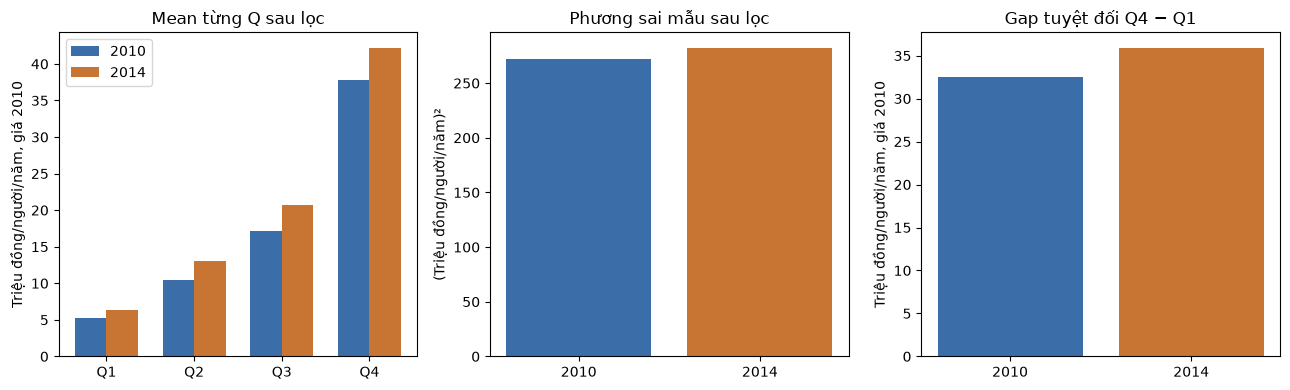

,question,conclusion
0,"1. Mean ngoài top 0,1% tăng?",Có bằng chứng theo CLT/SE trimmed mean; +16.73%
1,2. Mean từng Q tăng?,Cả bốn test riêng lẻ bác bỏ H₀ theo xấp xỉ; giữ Q gốc
2,3. Variance sau lọc giảm?,Mẫu tăng 3.86%; không quyết định H₀ bằng F
3,4. Gap tuyệt đối sau lọc giảm?,Chưa có bằng chứng giảm; mẫu tăng 3.431 triệu


In [10]:
figure, axes = plt.subplots(1, 3, figsize=(13, 4))
positions = np.arange(4)
for year, shift, color in [(2010, -.18, "#3B6EA8"), (2014, .18, "#C87533")]:
    group_means = [mean_estimators.loc[(year, f"Q{quartile}"), "mean"] for quartile in [1, 2, 3, 4]]
    axes[0].bar(positions + shift, group_means, width=.36, color=color, label=str(year))
axes[0].set_xticks(positions, ["Q1", "Q2", "Q3", "Q4"])
axes[0].set_title("Mean từng Q sau lọc")
axes[0].set_ylabel("Triệu đồng/người/năm, giá 2010")
axes[0].legend()
axes[1].bar(["2010", "2014"], [variance_2010, variance_2014], color=["#3B6EA8", "#C87533"])
axes[1].set_title("Phương sai mẫu sau lọc")
axes[1].set_ylabel("(Triệu đồng/người/năm)²")
axes[2].bar(["2010", "2014"], gap_by_year["absolute_gap"], color=["#3B6EA8", "#C87533"])
axes[2].set_title("Gap tuyệt đối Q4 − Q1")
axes[2].set_ylabel("Triệu đồng/người/năm, giá 2010")
figure.tight_layout()
plt.show()

final_summary = pd.DataFrame([
    {"question": "1. Mean ngoài top 0,1% tăng?", "conclusion": f"Có bằng chứng theo CLT/SE trimmed mean; +{overall_result['change_percent']:.2f}%"},
    {"question": "2. Mean từng Q tăng?", "conclusion": "Cả bốn test riêng lẻ bác bỏ H₀ theo xấp xỉ; giữ Q gốc"},
    {"question": "3. Variance sau lọc giảm?", "conclusion": f"Mẫu tăng {variance_change_percent:.2f}%; không quyết định H₀ bằng F"},
    {"question": "4. Gap tuyệt đối sau lọc giảm?", "conclusion": f"Chưa có bằng chứng giảm; mẫu tăng {gap_change:.3f} triệu"},
])
display(final_summary.style.set_properties(**{"white-space": "normal", "text-align": "left"}))

In [11]:
for year in YEARS:
    original = original_by_year[year]
    retained = retained_by_year[year]
    removed = removed_by_year[year]
    assert len(removed) == 10
    assert set(retained.index).isdisjoint(set(removed.index))
    assert len(retained) + len(removed) == len(original)
    assert sum(len(retained_samples[(year, f"Q{q}")]) for q in [1, 2, 3, 4]) == len(retained)
    for q in [1, 2, 3]:
        np.testing.assert_allclose(np.sort(original_samples[(year, f"Q{q}")]),
                                   np.sort(retained_samples[(year, f"Q{q}")]))
    np.testing.assert_allclose(
        retained["real_income_per_person"].mean(),
        sum(len(retained_samples[(year, f"Q{q}")]) * mean_estimators.loc[(year, f"Q{q}"), "mean"]
            for q in [1, 2, 3, 4]) / len(retained),
    )
np.testing.assert_allclose(
    gap_change,
    mean_results.set_index("scope").loc["Q4", "change"]
    - mean_results.set_index("scope").loc["Q1", "change"],
)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == original_excel_hash
sample_audit.to_csv(output_directory / "thu_nhap_bo_top_0_1_so_mau.csv", index=False)
removed_households.to_csv(output_directory / "thu_nhap_bo_top_0_1_ho_bi_loai.csv", index=False)
mean_results.to_csv(output_directory / "thu_nhap_bo_top_0_1_mean_tests.csv", index=False)
print("Đã kiểm tra bộ lọc, n các Q, mean toàn mẫu, SE, t/df/p của Q1–Q3 và gap. Excel gốc giữ nguyên.")

Đã kiểm tra bộ lọc, n các Q, mean toàn mẫu, SE, t/df/p của Q1–Q3 và gap. Excel gốc giữ nguyên.


**Phạm vi kết luận:** bản này đã loại top 0,1% ở cả hai năm theo yêu cầu. Các kết quả mean/gap là xấp xỉ lấy mẫu; công thức SE trimmed mean được ghi riêng là phần bổ sung ngoài slide. Câu phương sai có kết quả mô tả sau lọc, chưa có kiểm định F hợp lệ. Chưa kết luận mức sống toàn diện hoặc thu nhập của mọi hộ đều tăng.